In [1]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

import sys
sys.path.append('..')
from src import visualisation as vis

In [3]:
# Loading data
system_contact_dir = '../data/contact_definition/pipeline/sh3-prm'
system = {
    'pae': np.load(system_contact_dir+'/pae.npy'),
    'pinc': np.load(system_contact_dir+'/pinc.npy'),
    'min_dist': np.load(system_contact_dir+'/min_dist.npy'),
    'scm': np.load(system_contact_dir+'/scm.npy'),
    'contacts': np.load(system_contact_dir+'/contacts.npy'),
}
acceptor_chainid = 'A'
donor_chainid = 'B'

Text(366.88541666666663, 0.5, 'Acceptor residue')

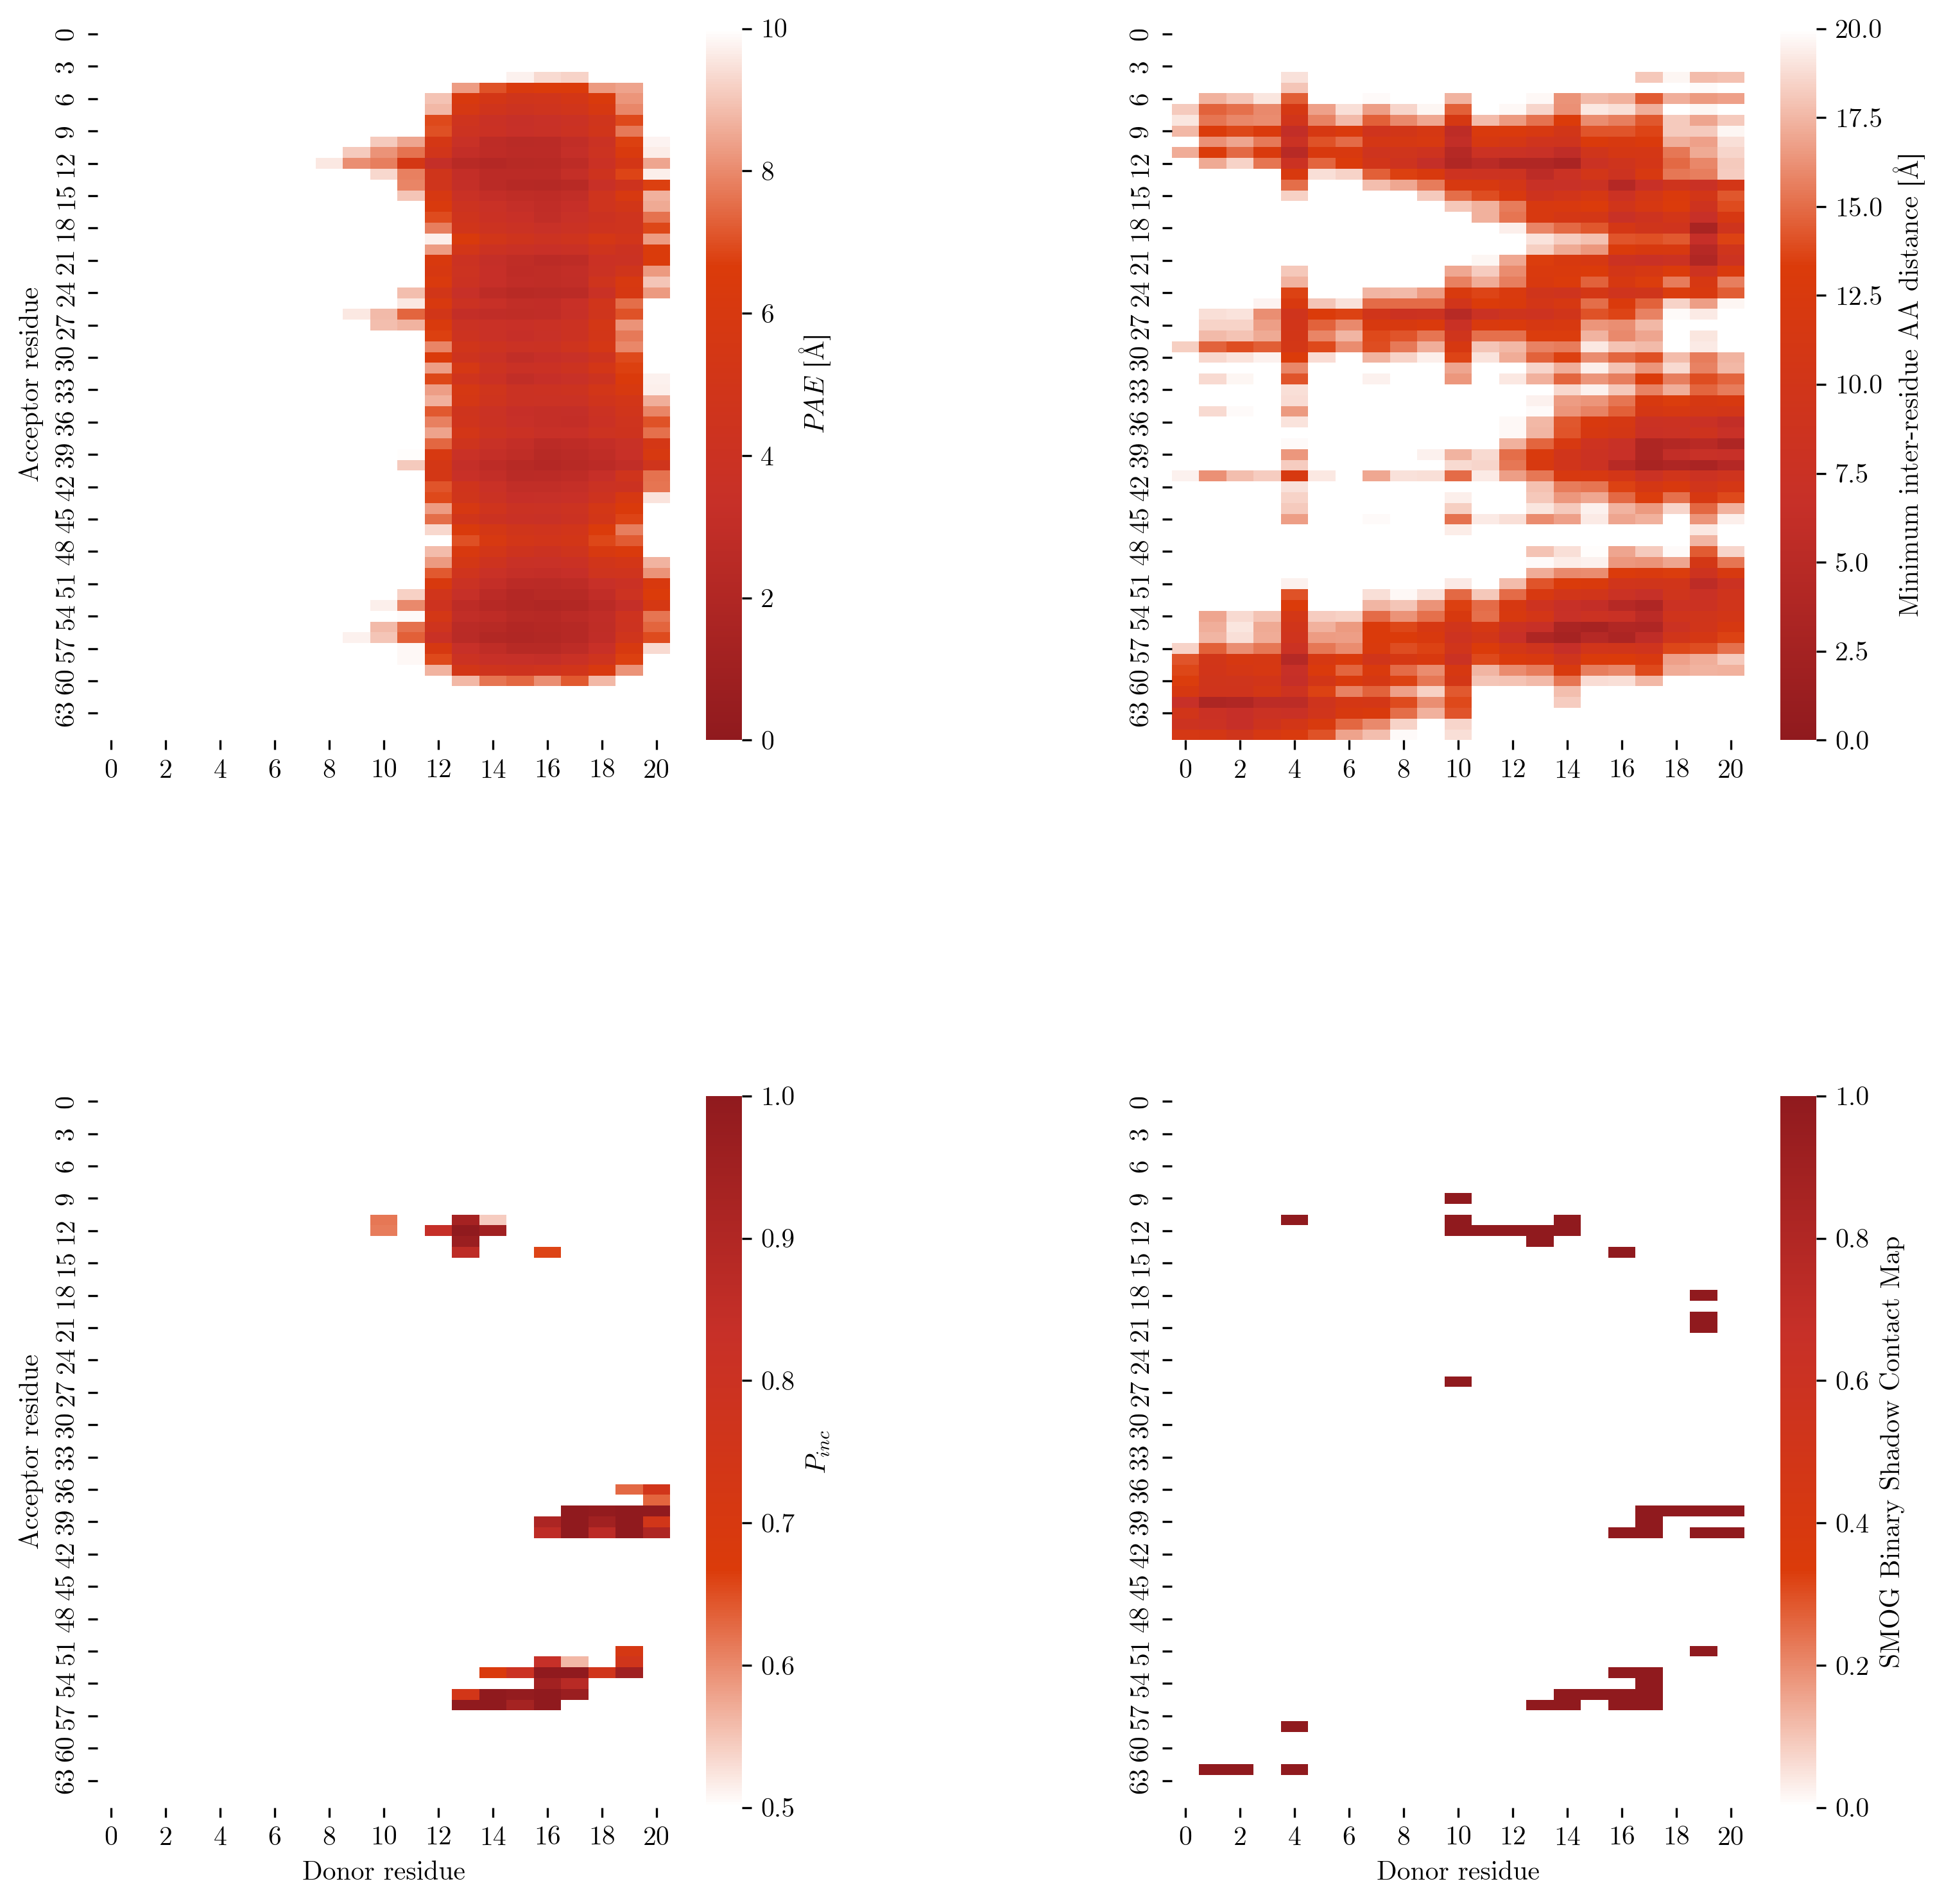

In [4]:
fig, axes = plt.subplots(2,2, figsize=(12,12))
plt.subplots_adjust(wspace=0.5, hspace=0.5)

sns.heatmap(
    system['pae'], vmin=0, vmax=10,
    cmap=vis.cmap.red_cmap.reversed(),
    cbar_kws=dict(label='$PAE$ [Å]'), ax=axes[0,0]
)


sns.heatmap(
    system['pinc'], vmin=0.5, vmax=1,
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='$P_{inc}$'), ax=axes[1,0]
)

sns.heatmap(
    system['min_dist'], vmin=0, vmax=20,
    cmap=vis.cmap.red_cmap.reversed(),
    cbar_kws=dict(label='Minimum inter-residue AA distance [Å]'), ax=axes[0,1]
)

sns.heatmap(
    system['scm'], vmin=0, vmax=1,
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='SMOG Binary Shadow Contact Map'), ax=axes[1,1]
)

axes[1,0].set_xlabel('Donor residue')
axes[1,1].set_xlabel('Donor residue')
axes[0,0].set_ylabel('Acceptor residue')
axes[1,0].set_ylabel('Acceptor residue')

In [6]:
# Defining contacts
contact_defs = np.array([
    system['pae'] < 5,
    system['pinc'] > 0.5,
    system['min_dist'] < 9,
    system['scm']
])

slim_pairs = np.argwhere(contact_defs.all(axis=0)) + 1
print("sel", end=' ')
print(f"/{acceptor_chainid}:"+",".join(np.unique(slim_pairs[:,0].astype(str))), end=' ')
print("|", end=' ')
print(f"/{donor_chainid}:"+",".join(np.unique(slim_pairs[:,1].astype(str))))

sel /A:12,13,14,15,39,40,41,52,54,55,56,57 | /B:13,14,15,16,17,18,19,20,21


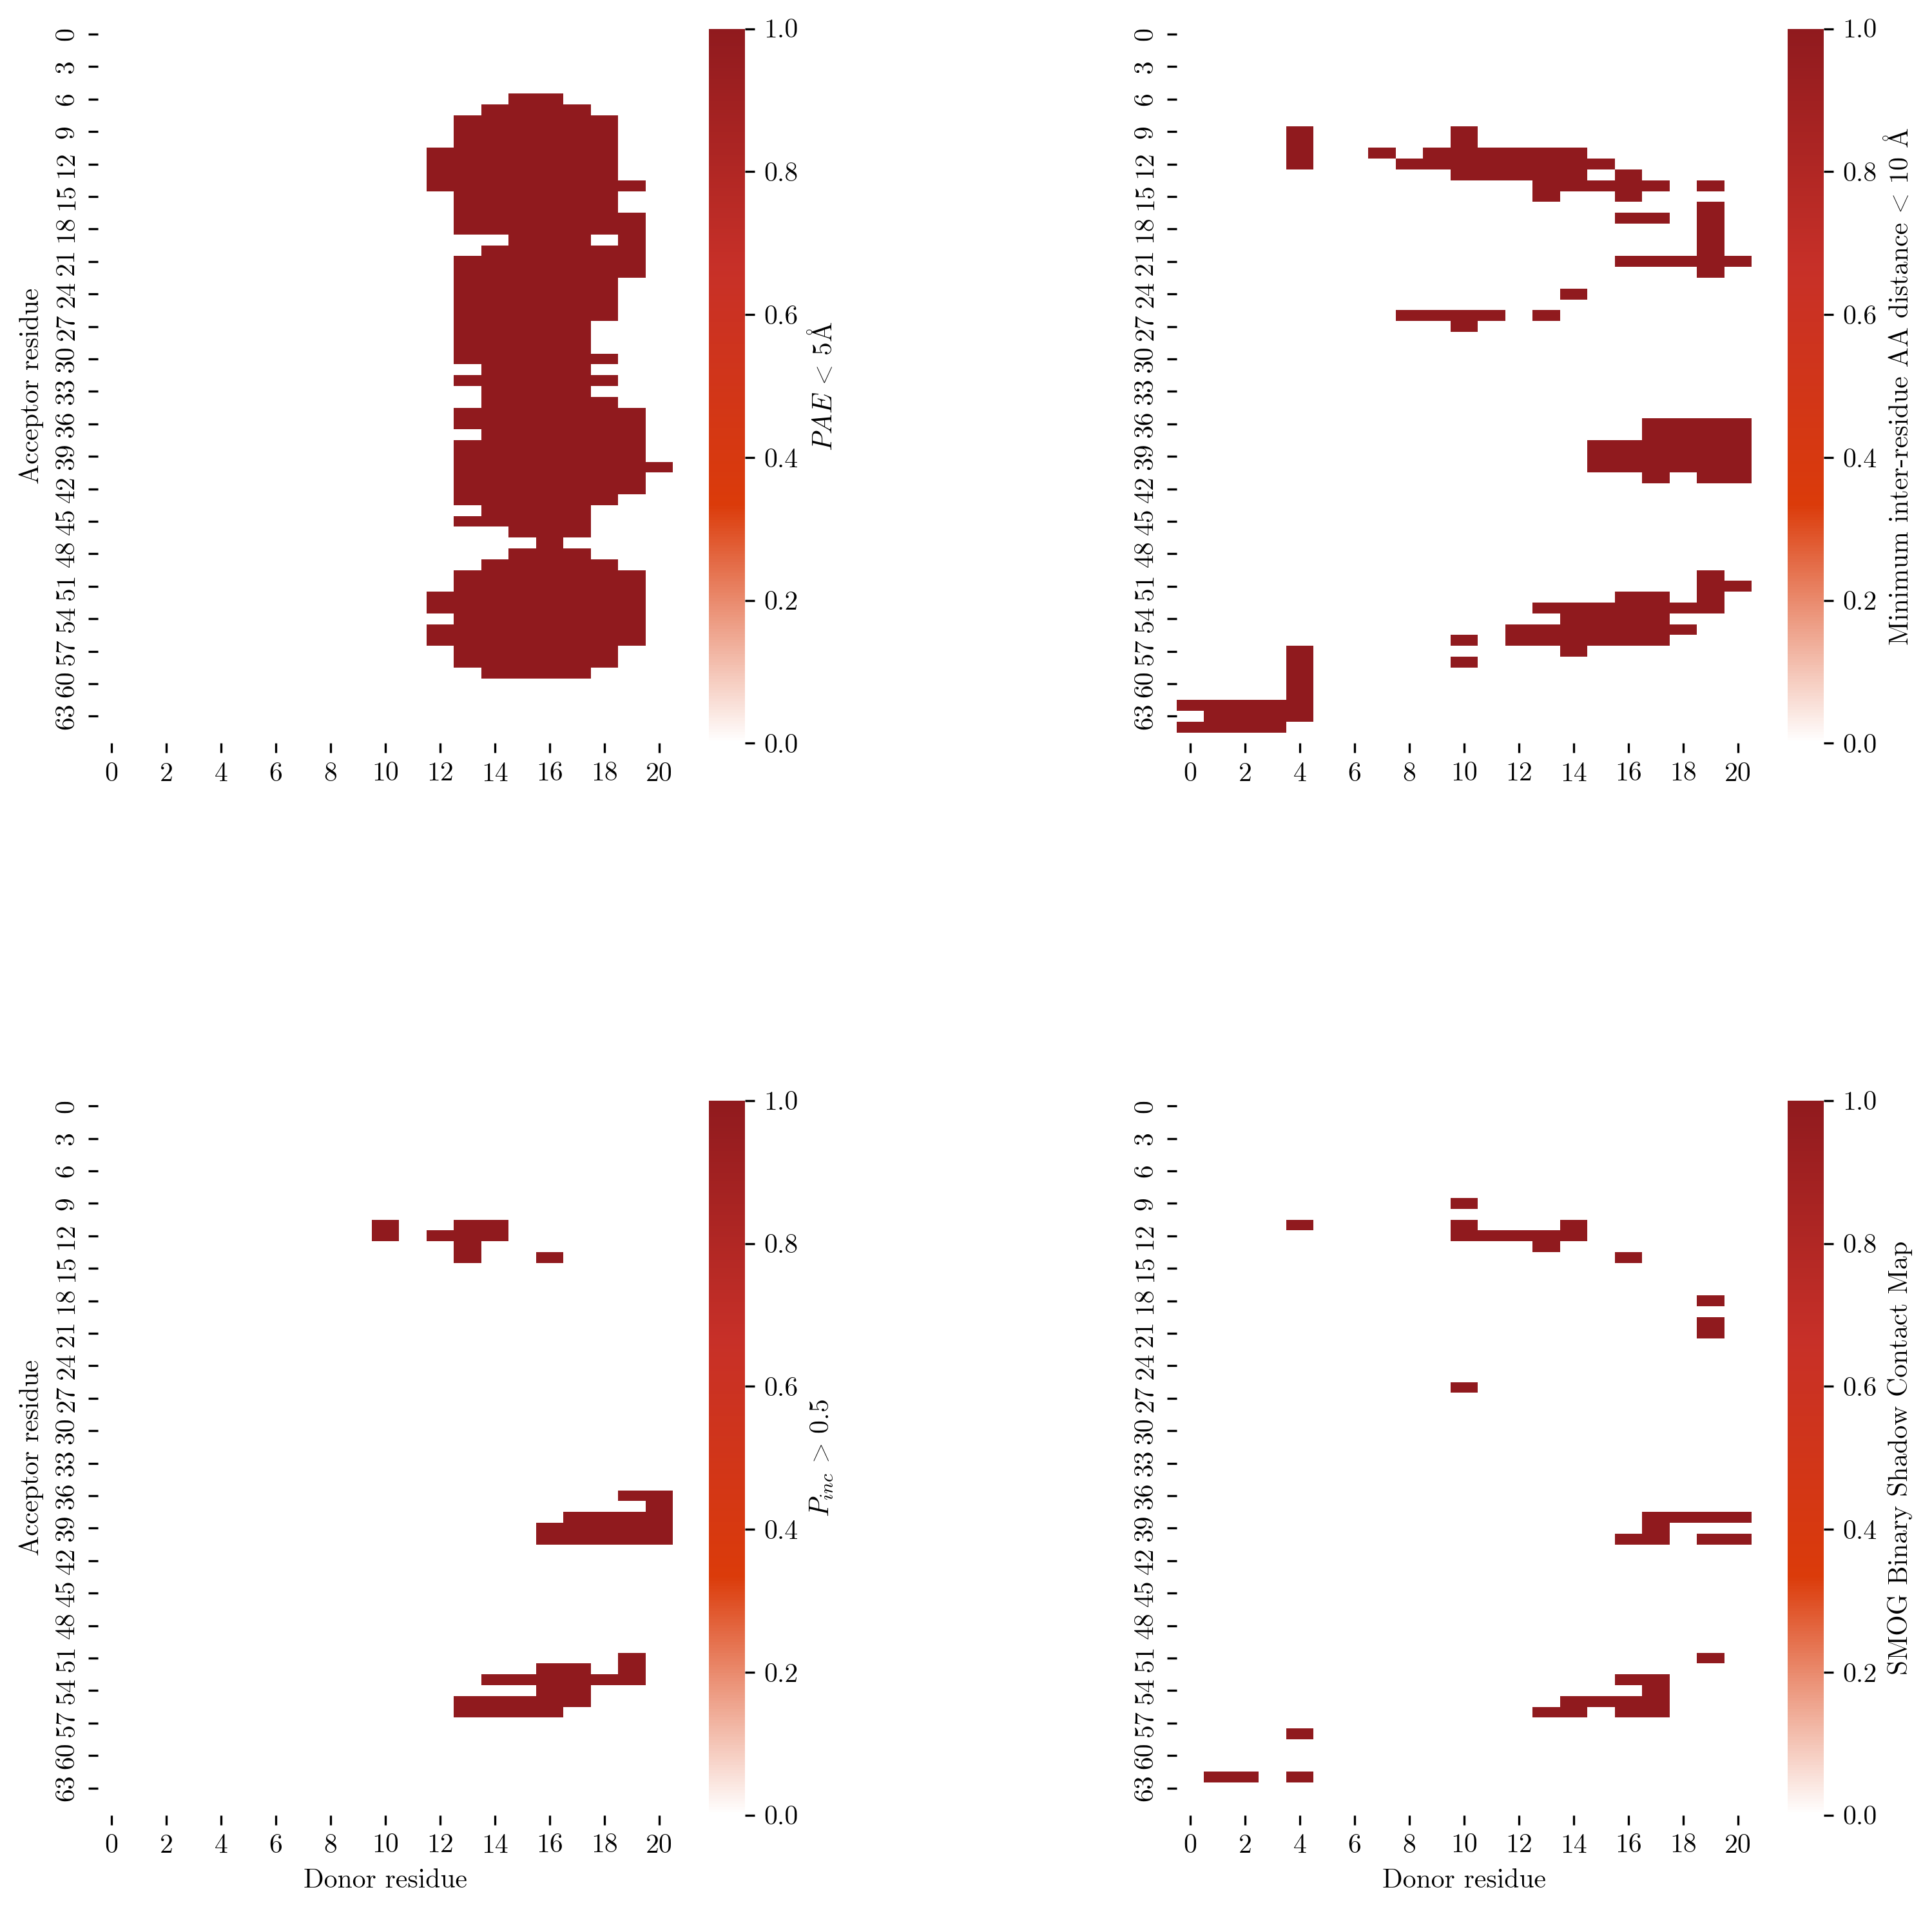

<Axes: >

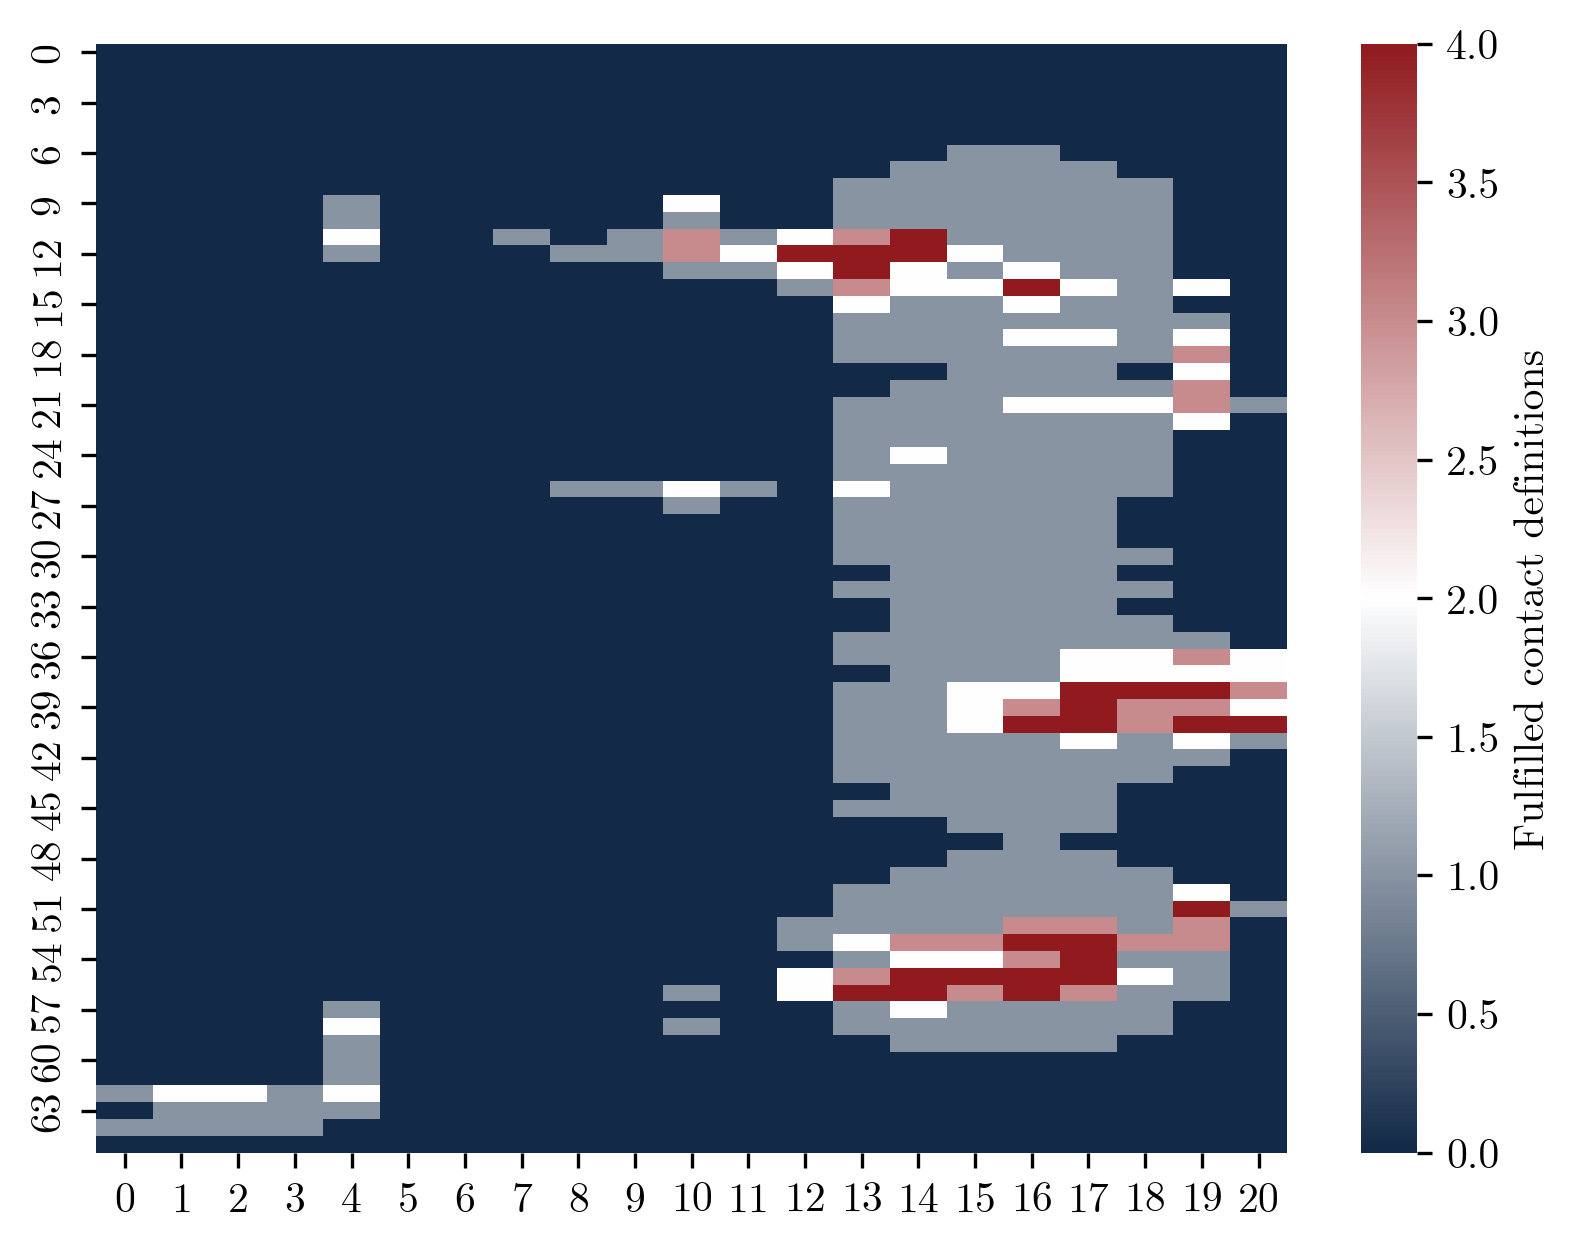

In [7]:
fig, axes = plt.subplots(2,2, figsize=(12,12))
plt.subplots_adjust(wspace=0.5, hspace=0.5)

sns.heatmap(
    contact_defs[0],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='$PAE$ < 5Å'), ax=axes[0,0]
)


sns.heatmap(
    contact_defs[1],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='$P_{inc}$ > 0.5'), ax=axes[1,0]
)

sns.heatmap(
    contact_defs[2],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='Minimum inter-residue AA distance < 10 Å'), ax=axes[0,1]
)

sns.heatmap(
    contact_defs[3],
    cmap=vis.cmap.red_cmap,
    cbar_kws=dict(label='SMOG Binary Shadow Contact Map'), ax=axes[1,1]
)

axes[1,0].set_xlabel('Donor residue')
axes[1,1].set_xlabel('Donor residue')
axes[0,0].set_ylabel('Acceptor residue')
axes[1,0].set_ylabel('Acceptor residue')

plt.show()

sns.heatmap(
    contact_defs.sum(axis=0),
    cmap=vis.cmap.diverging_cmap,
    cbar_kws=dict(label='Fulfilled contact definitions')
)

Text(0.5, 1.0, 'Number of inter-chain residue contacts fulfilling conditions')

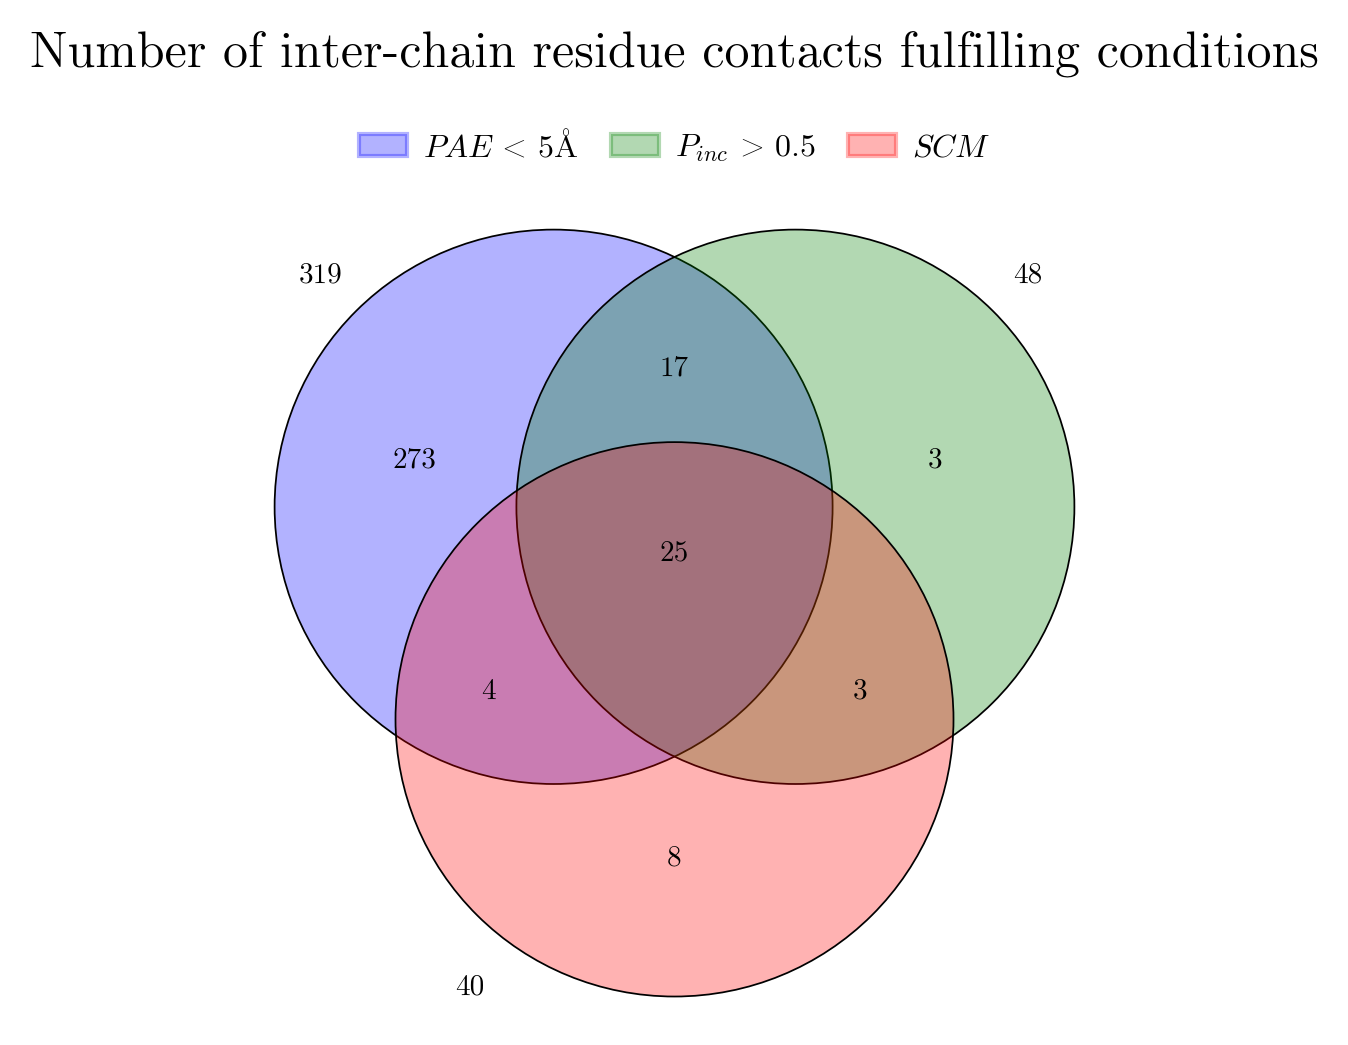

In [8]:
from matplotlib.figure import figaspect
from venny4py.venny4py import venny4py
sets = {
    '$PAE$ < 5Å': set(list(map(lambda p: str(p), np.argwhere(contact_defs[0])))),
    '$P_{inc}$ > 0.5': set(list(map(lambda p: str(p), np.argwhere(contact_defs[1])))),
#    '$MinDist$ < 10Å': set(list(map(lambda p: str(p), np.argwhere(contact_defs[2])))),
    '$SCM$': set(list(map(lambda p: str(p), np.argwhere(contact_defs[3]))))
}

fig, ax = plt.subplots(figsize=(4,4))   
venny4py(sets=sets, out='../.old/', asax=ax)
ax.set_title("Number of inter-chain residue contacts fulfilling conditions")

In [9]:
from src.analysis.alphafold import res_cg_dists
slim_eqdists = res_cg_dists(
    system_contact_dir+'/af_model.pdb',
    'A', 'B', slim_pairs
)

slims = pd.DataFrame({
    'Folded residue': slim_pairs[:,0],
    'Unfolded residue': slim_pairs[:,1],
    'Equilbrium distance [Å]': slim_eqdists
})
slims

,Folded residue,Unfolded residue,Equilbrium distance [Å]
0,12,15,8.707665
1,13,13,7.294567
2,13,14,4.783507
3,13,15,6.862138
4,14,14,7.550860
5,15,17,8.059139
6,39,18,7.138682
7,39,19,6.958369
8,39,20,5.727515
9,40,18,6.050554
